# Hotspots Comerciales · San Salvador

Estudiamos dónde se concentran los concesionarios y cómo se comparan tres ubicaciones propuestas para una posible sede Porsche. Las tablas y figuras que aparecen bajo cada celda son los resultados de ejecutar el código con los datos del proyecto.

## 1. Qué queremos comparar

Primero ubicamos los establecimientos registrados. Con **K-Means** identificamos grupos por cercanía. Con **KNN** asignamos las propuestas A, B y C a esos grupos. Finalmente contamos competidores en distintos radios y repetimos la comparación usando recorridos por carretera.

## 2. Preparación

Leemos los archivos incluidos en el proyecto. Usamos longitud y latitud para dibujar en el mapa y coordenadas UTM en metros para calcular distancias. La semilla 42 permite repetir el agrupamiento con el mismo conjunto de datos.

In [1]:
import json
import math
import sys
from pathlib import Path

import geopandas as gpd
%matplotlib inline
import matplotlib.pyplot as plt
from PIL import Image
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from pyproj import Transformer
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
BACKEND = RAIZ / "backend"
DATOS = BACKEND / "datos"
sys.path.insert(0, str(BACKEND))
import modelo

A_METROS = Transformer.from_crs("EPSG:4326", "EPSG:32616", always_xy=True)
A_GRADOS = Transformer.from_crs("EPSG:32616", "EPSG:4326", always_xy=True)
SEMILLA = 42
COLORES = {"Zona 1": "#196578", "Zona 2": "#aa5417"}
plt.rcParams.update({"figure.dpi": 115, "axes.formatter.useoffset": False, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)
print("Carpeta del backend:", BACKEND.relative_to(RAIZ))

Carpeta del backend: backend


## 3. Datos

Recopilamos los establecimientos con una exportación de Overpass Turbo usando la etiqueta `shop=car`. La primera tabla muestra cinco ejemplos. Cada fila identifica un establecimiento por su ID de OSM y sus dos coordenadas.

In [2]:
crudo = json.loads((DATOS / "concesionarios.geojson").read_text(encoding="utf-8"))
filas = []
for f in crudo["features"]:
    lon, lat = f["geometry"]["coordinates"][:2]
    filas.append({"osm_id": f["id"], "name": f["properties"].get("name"), "latitude": lat, "longitude": lon})
osm = pd.DataFrame(filas)
print("Fecha de extracción:", crudo.get("timestamp"))
print("Registros:", len(osm))
osm.head()

Fecha de extracción: 2026-11-09T18:02:18Z
Registros: 30


,osm_id,name,latitude,longitude
0,way/140081410,General de Equipos (CAT),13.687773,-89.229324
1,way/374904202,Trans-Auto Navarra,13.675373,-89.206220
2,way/378182134,Excel Automotriz (BMW),13.702069,-89.235530
3,way/379809036,CrediQ,13.682898,-89.226322
4,way/395681945,Grupo Q,13.684632,-89.222455


## 4. Limpieza

Revisamos coordenadas, duplicados y actividad comercial. **Excluimos** un registro cuando verificamos que no
vende vehículos y lo dejamos **pendiente** cuando hay señales de que podría no ser concesionario. Ninguno de los
dos entra en el entrenamiento. La columna «motivo» permite comprobar por qué un establecimiento quedó fuera.

In [3]:
osm = osm.dropna(subset=["latitude", "longitude"])
osm = osm[osm.latitude.between(-90, 90) & osm.longitude.between(-180, 180)]
osm = osm.drop_duplicates("osm_id").drop_duplicates(["latitude", "longitude"]).reset_index(drop=True)

def estado(oid):
    if oid in modelo.EXCLUSIONES_CONFIRMADAS:
        return "excluido_confirmado"
    if oid in modelo.REVISION_PENDIENTE:
        return "pendiente_revision"
    return "sin_alerta"

osm["estado"] = osm.osm_id.map(estado)
osm["motivo"] = osm.osm_id.map(lambda o: modelo.EXCLUSIONES_CONFIRMADAS.get(o, (None, ""))[1]
                               or modelo.REVISION_PENDIENTE.get(o, ""))
osm.loc[osm.osm_id.isin(modelo.EXCLUSIONES_CONFIRMADAS), "name"] = "Total Auto Service"
display(osm.estado.value_counts().rename("registros").to_frame())
osm[osm.estado != "sin_alerta"][["name", "estado", "motivo"]]

,registros
estado,
sin_alerta,23
pendiente_revision,6
excluido_confirmado,1


,name,estado,motivo
0,General de Equipos (CAT),pendiente_revision,Maquinaria CAT: verificar venta de automóviles
3,CrediQ,pendiente_revision,CrediQ: verificar que esta sede venda vehículo...
8,Total Auto Service,excluido_confirmado,"Taller de mantenimiento y reparación, no conce..."
10,Taller Excel Automotriz,pendiente_revision,Taller Excel Automotriz: posible taller
21,ASESUISA,pendiente_revision,ASESUISA: posible aseguradora
24,Yamaha Roosevelt,pendiente_revision,Yamaha Roosevelt: verificar si vende automóvil...
25,TNT EXPRESS S.A DE C.V,pendiente_revision,TNT EXPRESS: posible servicio de logística


## 5. Análisis exploratorio

Proyectamos las coordenadas a UTM 16N para medir en metros. Luego aplicamos un filtro exploratorio de 5 km
alrededor de la mediana para separar los establecimientos muy alejados del núcleo comercial. En la figura izquierda, cada punto corresponde a un registro. En el histograma, cada barra cuenta cuántos negocios caen en un intervalo de distancia.

Elegibles: 23 | en el núcleo de 5 km: 21


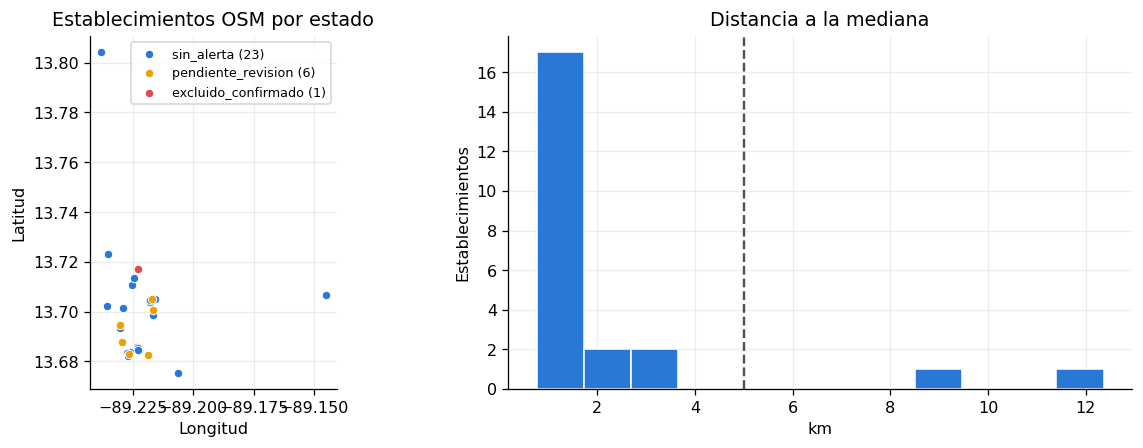

In [4]:
x, y = A_METROS.transform(osm.longitude.to_numpy(), osm.latitude.to_numpy())
osm["x_m"], osm["y_m"] = x, y
elegibles = osm[osm.estado == "sin_alerta"].copy()
mediana = np.median(elegibles[["x_m", "y_m"]], axis=0)
elegibles["dist_mediana_m"] = np.hypot(elegibles.x_m - mediana[0], elegibles.y_m - mediana[1])
nucleo = elegibles[elegibles.dist_mediana_m <= 5000].copy()
print("Elegibles:", len(elegibles), "| en el núcleo de 5 km:", len(nucleo))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for est, color in [("sin_alerta", "#2a78d6"), ("pendiente_revision", "#eda100"), ("excluido_confirmado", "#e34948")]:
    d = osm[osm.estado == est]
    ax[0].scatter(d.longitude, d.latitude, s=28, c=color, label=f"{est} ({len(d)})", edgecolors="white", linewidths=0.6)
ax[0].set(title="Establecimientos OSM por estado", xlabel="Longitud", ylabel="Latitud")
ax[0].legend(fontsize=8)
ax[1].hist(elegibles.dist_mediana_m / 1000, bins=12, color="#2a78d6", edgecolor="white")
ax[1].axvline(5, color="#52514e", ls="--")
ax[1].set(title="Distancia a la mediana", xlabel="km", ylabel="Establecimientos")
ax[0].set_aspect(1 / np.cos(np.deg2rad(osm.latitude.mean())))
for eje in ax:
    eje.grid(alpha=.22)
    eje.set_axisbelow(True)
plt.tight_layout()
plt.show()

> **Qué mostramos.** La posición de los 30 establecimientos según su estado y su distancia a la mediana del grupo.
>
> **Qué significa.** La mayoría se concentra a menos de 5 km; dos quedan claramente alejados del núcleo.
>
> **Qué concluimos.** Trabajamos con 21 concesionarios cercanos entre sí. Es una muestra pequeña que depende de la cobertura de OSM.

## 6. K-Means

Utilizamos K-Means para identificar zonas donde los concesionarios están cerca unos de otros. El algoritmo
coloca *k* centros, asigna cada concesionario al más cercano y mueve los centros al promedio hasta estabilizarse.

Probamos de 2 a 6 grupos. Como ambas variables están en metros, no las escalamos. Elegimos el mayor coeficiente
silhouette entre las opciones cuyo grupo más pequeño tenga al menos 3 concesionarios.

In [5]:
X = nucleo[["x_m", "y_m"]].to_numpy()
evaluacion = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20).fit(X)
    evaluacion.append({"k": k, "silhouette": silhouette_score(X, km.labels_),
                       "inercia": km.inertia_, "grupo_minimo": np.bincount(km.labels_).min()})
evaluacion = pd.DataFrame(evaluacion)
validas = evaluacion[evaluacion.grupo_minimo >= 3]
K = int(validas.loc[validas.silhouette.idxmax(), "k"])
km = KMeans(n_clusters=K, random_state=SEMILLA, n_init=20).fit(X)

# Numeramos las zonas de oeste a este para que el resultado sea estable.
orden = np.argsort(km.cluster_centers_[:, 0])
renumerar = {int(viejo): i + 1 for i, viejo in enumerate(orden)}
nucleo["zona"] = [f"Zona {renumerar[int(e)]}" for e in km.labels_]
centroides = pd.DataFrame([{"zona": f"Zona {renumerar[int(j)]}",
                            "longitude": A_GRADOS.transform(*km.cluster_centers_[j])[0],
                            "latitude": A_GRADOS.transform(*km.cluster_centers_[j])[1],
                            "concesionarios": int((km.labels_ == j).sum())} for j in orden])
print("k elegido:", K)
display(evaluacion.round(3))
centroides

k elegido: 2


,k,silhouette,inercia,grupo_minimo
0,2,0.594,1.807802e+07,9
1,3,0.560,1.232734e+07,4
2,4,0.582,7.545529e+06,1
3,5,0.639,3.657878e+06,1
4,6,0.651,1.866014e+06,1


,zona,longitude,latitude,concesionarios
0,Zona 1,-89.224102,13.706985,9
1,Zona 2,-89.223338,13.684188,12


## 7. Cómo elegimos el número de grupos

El *silhouette* mide qué tan bien separado está un grupo de los demás. La inercia suma las distancias al cuadrado de los puntos a sus centroides. Leemos ambos gráficos junto con el tamaño del grupo más pequeño. La tercera figura muestra en qué parte del plano quedó cada grupo.

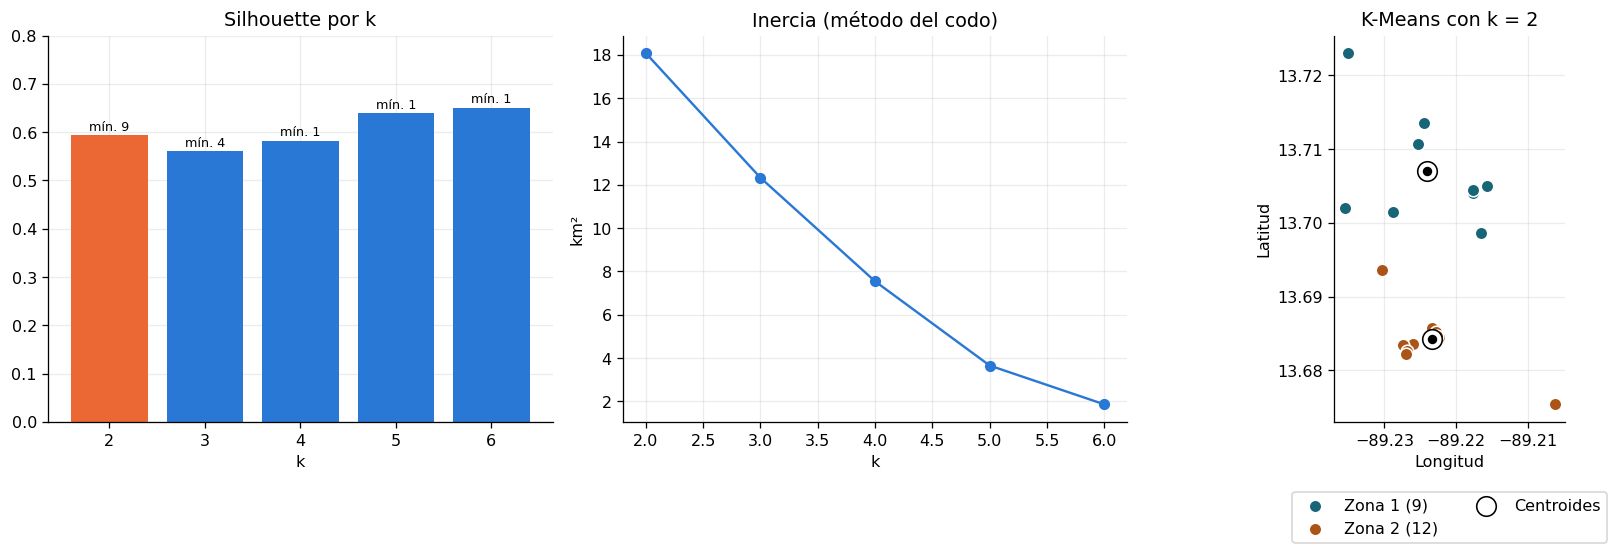

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
colores = ["#eb6834" if k == K else "#2a78d6" for k in evaluacion.k]
ax[0].bar(evaluacion.k, evaluacion.silhouette, color=colores)
for k, s, g in evaluacion[["k", "silhouette", "grupo_minimo"]].itertuples(index=False):
    ax[0].text(k, s + 0.01, f"mín. {g}", ha="center", fontsize=8)
ax[0].set(title="Silhouette por k", xlabel="k", ylim=(0, 0.8))
ax[1].plot(evaluacion.k, evaluacion.inercia / 1e6, marker="o", color="#2a78d6")
ax[1].set(title="Inercia (método del codo)", xlabel="k", ylabel="km²")
for zona, d in nucleo.groupby("zona"):
    ax[2].scatter(d.longitude, d.latitude, s=62, c=COLORES[zona], label=f"{zona} ({len(d)})", edgecolors="white")
ax[2].scatter(centroides.longitude, centroides.latitude, marker="o", s=150, c="white", edgecolors="black", label="Centroides")
ax[2].scatter(centroides.longitude, centroides.latitude, s=24, c="black", zorder=4)
ax[2].set_aspect(1 / np.cos(np.deg2rad(nucleo.latitude.mean())))
ax[2].set(title=f"K-Means con k = {K}", xlabel="Longitud", ylabel="Latitud")
ax[2].legend(fontsize=8)
ax[2].legend(loc="upper center", bbox_to_anchor=(.5,-.16), ncol=2)
for eje in ax:
    eje.grid(alpha=.23)
    eje.set_axisbelow(True)
plt.tight_layout()
plt.show()

> **Qué mostramos.** La calidad de la separación (silhouette), la inercia y las dos zonas resultantes.
>
> **Qué significa.** Con k ≥ 4 el silhouette es similar o mayor, pero aparecen grupos de un solo concesionario,
> que no representan una zona. La Zona 1 (norte) reúne 9 concesionarios y la Zona 2 (sur) 12, más compacta.
>
> **Qué concluimos.** Mantenemos k = 2. Cada diana representa el centro de un grupo. Las tres ubicaciones propuestas se evalúan por separado.

## 8. KNN

Utilizamos KNN para clasificar ubicaciones nuevas: cada punto toma la zona de la mayoría de sus 3 concesionarios
más cercanos. Para evaluarlo retiramos un concesionario cada vez (leave-one-out) y comparamos la zona predicha con
la de K-Means. Esto mide **coherencia** con K-Means, no precisión comercial.

,k,acuerdo_loo
0,1,0.952
1,3,0.952
2,5,1.000
3,7,1.000
4,9,1.000


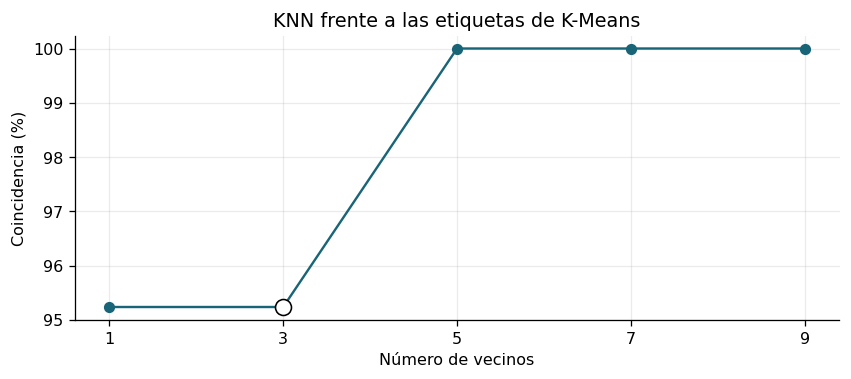

In [7]:
etiquetas = nucleo.zona.to_numpy()
knn_eval = pd.DataFrame([{"k": k, "acuerdo_loo": accuracy_score(
    etiquetas, cross_val_predict(KNeighborsClassifier(n_neighbors=k), X, etiquetas, cv=LeaveOneOut()))}
    for k in (1, 3, 5, 7, 9)])
knn = KNeighborsClassifier(n_neighbors=3).fit(X, etiquetas)
display(knn_eval.round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(knn_eval.k, knn_eval.acuerdo_loo*100, "o-", color=COLORES["Zona 1"])
ax.scatter(3, 100*knn_eval.loc[knn_eval.k == 3,"acuerdo_loo"].iloc[0], s=100, facecolor="white", edgecolor="black", zorder=3)
ax.set(xlabel="Número de vecinos", ylabel="Coincidencia (%)", title="KNN frente a las etiquetas de K-Means", xticks=knn_eval.k)
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

> **Qué mostramos.** El porcentaje de coincidencia entre KNN y K-Means para 1, 3, 5, 7 y 9 vecinos.
>
> **Qué significa.** Con 3 vecinos coincide en el 95.2 % de los casos; con 5 o más llega al 100 %.
>
> **Qué concluimos.** Mantenemos 3 vecinos, el valor original del proyecto. KNN reproduce bien las zonas geográficas.

## 9. Ubicaciones propuestas

Para cada propuesta, medimos la distancia hasta los 21 concesionarios. Los tres primeros definen su zona KNN. Los conteos a 500 m, 1 km y 2 km incluyen todos los que caben en ese radio, incluso si son más de tres.

In [8]:
ubic = pd.read_csv(DATOS / "ubicaciones_propuestas.csv")
filas, vecinos = [], []
for u in ubic.itertuples():
    p = np.array([A_METROS.transform(u.longitude, u.latitude)])
    dist = np.hypot(*(X - p).T)
    d3, i3 = knn.kneighbors(p, n_neighbors=3)
    filas.append({"id": u.id, "zona_knn": knn.predict(p)[0], "a_500m": int((dist <= 500).sum()),
                  "a_1km": int((dist <= 1000).sum()), "a_2km": int((dist <= 2000).sum()),
                  "mas_cercano_m": round(dist.min(), 1), "tercer_vecino_m": round(d3[0][-1], 1)})
    vecinos += [{"id": u.id, "vecino": nucleo.iloc[i]["name"], "zona": nucleo.iloc[i].zona, "distancia_m": round(d, 1),
                 "este_m": X[i,0]-p[0,0], "norte_m": X[i,1]-p[0,1]}
                for d, i in zip(d3[0], i3[0])]
clasificacion = pd.DataFrame(filas)

# Comprobamos que el backend produce exactamente lo mismo.
df_b, _ = modelo.leer_concesionarios()
m_b = modelo.entrenar(df_b)
for u in ubic.itertuples():
    r = modelo.clasificar_punto(u.latitude, u.longitude, m_b)
    fila = clasificacion[clasificacion.id == u.id].iloc[0]
    assert r["zona_knn"] == fila.zona_knn and r["concesionarios_1km"] == fila.a_1km
print("Resultados idénticos a los del backend.")
display(clasificacion)
tabla_vecinos = pd.DataFrame(vecinos)
display(tabla_vecinos[["id", "vecino", "zona", "distancia_m"]])

Resultados idénticos a los del backend.


,id,zona_knn,a_500m,a_1km,a_2km,mas_cercano_m,tercer_vecino_m
0,A,Zona 1,1,5,16,400.4,559.9
1,B,Zona 2,10,10,13,185.2,235.9
2,C,Zona 1,2,2,9,76.7,1234.0


,id,vecino,zona,distancia_m
0,A,Nicekar,Zona 1,400.4
1,A,Excel Usados,Zona 1,511.3
2,A,Kia Motors,Zona 1,559.9
3,B,CrediQ Usados Seguros,Zona 2,185.2
4,B,Grupo Q Usados,Zona 2,200.1
5,B,Grupo Q,Zona 2,235.9
6,C,HS Import's,Zona 1,76.7
7,C,F & A Imports,Zona 1,252.7
8,C,Kia Motors,Zona 1,1234.0


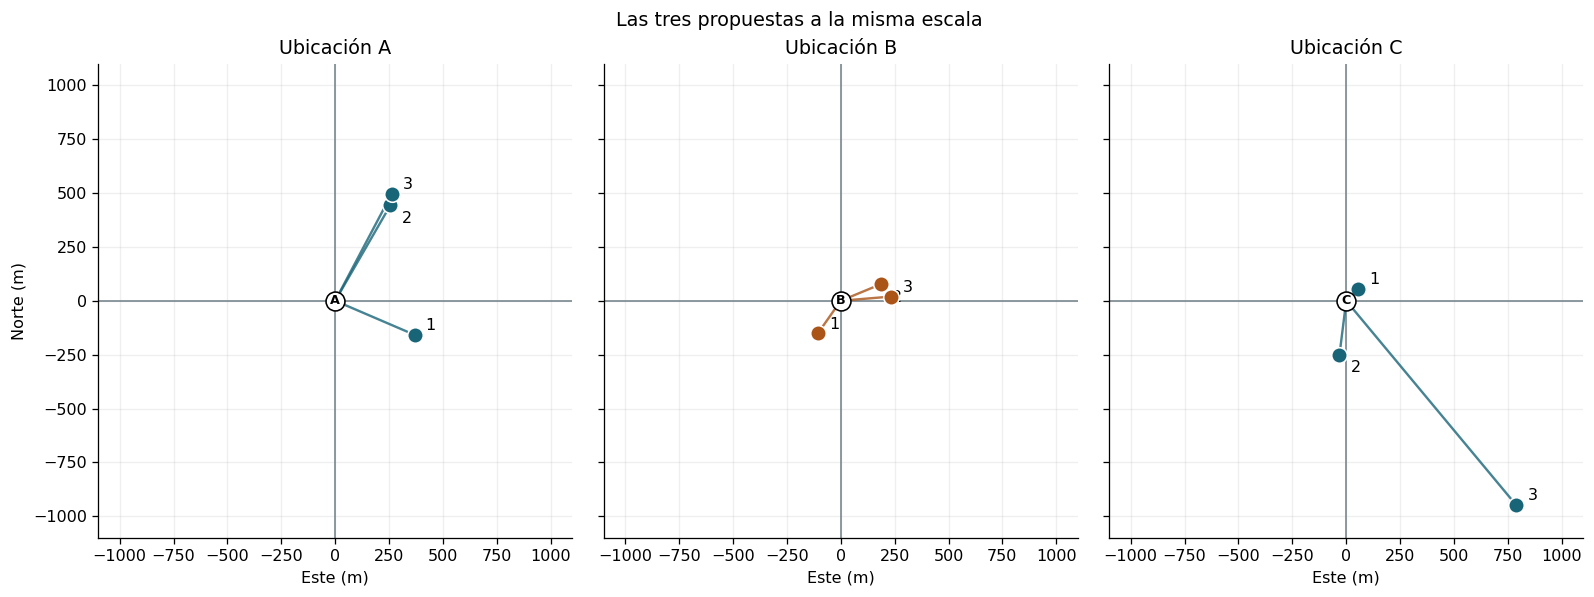

In [9]:
fig, ejes = plt.subplots(1, len(ubic), figsize=(14, 5), sharex=True, sharey=True)
limite = np.ceil(tabla_vecinos[["este_m", "norte_m"]].abs().max().max()/250)*250 + 100
for ax, (propuesta, grupo) in zip(ejes, tabla_vecinos.groupby("id", sort=False)):
    ax.axhline(0, color="#73838a", linewidth=1)
    ax.axvline(0, color="#73838a", linewidth=1)
    for numero, vecino in enumerate(grupo.itertuples(), 1):
        ax.plot([0, vecino.este_m], [0, vecino.norte_m], color=COLORES[vecino.zona], alpha=.8)
        ax.scatter(vecino.este_m, vecino.norte_m, s=95, facecolor=COLORES[vecino.zona], edgecolor="white", zorder=3)
        ax.annotate(str(numero), (vecino.este_m, vecino.norte_m), xytext=(7, 3 if numero%2 else -11), textcoords="offset points")
    ax.scatter(0,0,s=140,facecolor="white",edgecolor="black",zorder=4)
    ax.text(0,0,propuesta,ha="center",va="center",weight="bold",fontsize=8,zorder=5)
    ax.set(title=f"Ubicación {propuesta}", xlabel="Este (m)",xlim=(-limite,limite),ylim=(-limite,limite),aspect="equal")
    ax.grid(alpha=.20)
ejes[0].set_ylabel("Norte (m)")
fig.suptitle("Las tres propuestas a la misma escala")
plt.tight_layout()
plt.show()

> **Qué mostramos.** La zona asignada a A, B y C, sus vecinos más cercanos y los concesionarios en distintos radios.
>
> **Qué significa.** A y C pertenecen a la Zona 1 y B a la Zona 2. B tiene 10 concesionarios a 1 km; C tiene 2, pero uno a 77 m.
>
> **Qué concluimos.** KNN clasifica la posición de cada ubicación; no predice sus ventas.

En cada plano el origen es la propuesta. Derecha significa este y arriba significa norte. Los números 1, 2 y 3 siguen el orden de la tabla, del vecino más próximo al más lejano.

## 10. Censo 2024

Distinguimos cuatro niveles: **departamento** de San Salvador, **municipio** San Salvador Centro, **distrito**
de San Salvador y el **área de estudio** (entorno de los concesionarios). Obtenemos el distrito de cada punto con
una unión espacial sobre los polígonos OPAMSS. La población es de todo el distrito y no equivale a compradores.

In [10]:
censo = pd.read_csv(BACKEND / "datos_censo" / "poblacion_2024.csv", dtype={"codigo_distrito": str})
niveles = pd.Series({
    "Departamento de San Salvador": censo[censo.departamento == "San Salvador"].poblacion_2024.sum(),
    "Municipio San Salvador Centro": censo[censo.municipio == "San Salvador Centro"].poblacion_2024.sum(),
    "Distrito de San Salvador": censo[censo.distrito == "San Salvador"].poblacion_2024.iloc[0],
}, name="Población 2024")
display(niveles.map("{:,}".format).to_frame())

distritos = gpd.read_file(BACKEND / "datos_geograficos" / "distritos_opamss.geojson").to_crs("EPSG:4326")
distritos["distrito"] = distritos.distritos.str.title()
distritos = distritos.dissolve(by="distrito", as_index=False)
puntos = gpd.GeoDataFrame(ubic, geometry=gpd.points_from_xy(ubic.longitude, ubic.latitude), crs="EPSG:4326")
unidos = gpd.sjoin(puntos, distritos[["distrito", "geometry"]], how="left", predicate="within")
unidos[["id", "distrito"]].merge(censo[["distrito", "municipio", "poblacion_2024"]], on="distrito", how="left")

,Población 2024
Departamento de San Salvador,"1,563,371"
Municipio San Salvador Centro,"673,319"
Distrito de San Salvador,"330,543"


,id,distrito,municipio,poblacion_2024
0,A,San Salvador,San Salvador Centro,330543
1,B,San Salvador,San Salvador Centro,330543
2,C,San Salvador,San Salvador Centro,330543


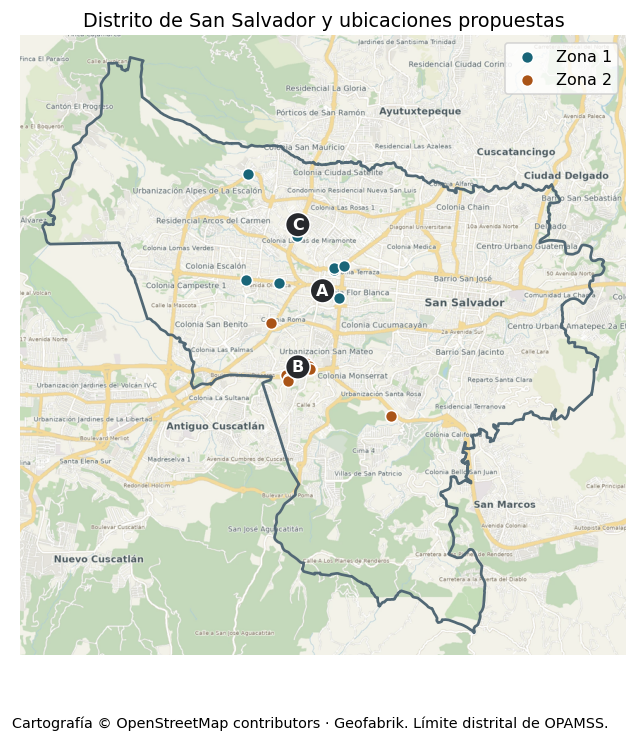

In [11]:
cartografia = RAIZ / "frontend" / "public" / "cartografia"
web = Transformer.from_crs(4326, 3857, always_xy=True)
def mapa_base(ax):
    oeste, sur = web.transform(-89.36, 13.59)
    este, norte = web.transform(-89.06, 13.82)
    ax.imshow(imagen_ciudad, extent=(oeste, este, sur, norte), origin="upper", zorder=0)

with Image.open(cartografia / "ciudad.webp") as imagen:
    imagen.thumbnail((2100, 2100))
    imagen_ciudad = np.asarray(imagen.convert("RGB"))

fig, ax = plt.subplots(figsize=(9.5, 7))
mapa_base(ax)
distrito = distritos[distritos.distrito == "San Salvador"].to_crs(3857)
distrito.boundary.plot(ax=ax, color="#516875", linewidth=1.7)
for zona, grupo in nucleo.groupby("zona"):
    ax.scatter(*web.transform(grupo.longitude, grupo.latitude), s=56, color=COLORES[zona], edgecolor="white", label=zona, zorder=4)
for u in ubic.itertuples():
    x, y = web.transform(u.longitude,u.latitude)
    ax.annotate(u.id,(x,y),color="white",weight="bold",ha="center",va="center",bbox=dict(boxstyle="circle",fc="#27292d",ec="white"), zorder=5)
x0,y0,x1,y1 = distrito.total_bounds
ax.set(xlim=(x0-500,x1+500),ylim=(y0-500,y1+500),title="Distrito de San Salvador y ubicaciones propuestas")
ax.legend(loc="upper right")
ax.set_axis_off()
fig.text(.5,.02,"Cartografía © OpenStreetMap contributors · Geofabrik. Límite distrital de OPAMSS.",ha="center",fontsize=9)
plt.show()

> **Qué mostramos.** El distrito de San Salvador sobre los polígonos OPAMSS, los concesionarios por zona y las tres ubicaciones.
>
> **Qué significa.** A, B y C están en el mismo distrito, con 330,543 habitantes en 2024.
>
> **Qué concluimos.** La población distrital no permite diferenciar las tres ubicaciones; haría falta información por zona.

## 11. Análisis vial

Utilizamos la red de calles para automóvil guardada en `red_vial.graphml` (no la descargamos de nuevo).
Conectamos cada punto al nodo más cercano y calculamos la ruta más corta con Dijkstra usando la longitud de cada
tramo. No convertimos las distancias a tiempos porque no tenemos velocidades verificadas.

In [12]:
G = ox.io.load_graphml(BACKEND / "datos_geograficos" / "red_vial.graphml")
print("Nodos:", len(G.nodes), "| tramos:", len(G.edges))

def nodo_y_separacion(lon, lat):
    n = ox.distance.nearest_nodes(G, X=lon, Y=lat)
    x1, y1 = A_METROS.transform(lon, lat)
    x2, y2 = A_METROS.transform(G.nodes[n]["x"], G.nodes[n]["y"])
    return n, math.hypot(x2 - x1, y2 - y1)

destinos = [(r.name, *nodo_y_separacion(r.longitude, r.latitude)) for r in nucleo.itertuples()]
vial = []
for u in ubic.itertuples():
    origen, snap = nodo_y_separacion(u.longitude, u.latitude)
    largos = nx.single_source_dijkstra_path_length(G, origen, weight="length")
    d = pd.Series({nombre: largos.get(n) for nombre, n, _ in destinos}).dropna().sort_values()
    vial.append({"id": u.id, "separacion_red_m": round(snap, 1), "rutas_validas": len(d),
                 "a_1km_por_calle": int((d <= 1000).sum()), "a_2km_por_calle": int((d <= 2000).sum()),
                 "mas_cercano": d.index[0], "mas_cercano_m": round(d.iloc[0], 1)})
vial = pd.DataFrame(vial)
vial

Nodos: 3242 | tramos: 7003


,id,separacion_red_m,rutas_validas,a_1km_por_calle,a_2km_por_calle,mas_cercano,mas_cercano_m
0,A,73.4,20,1,10,Nicekar,811.9
1,B,59.3,20,4,9,Grupo Q,172.0
2,C,33.6,20,2,6,F & A Imports,231.1


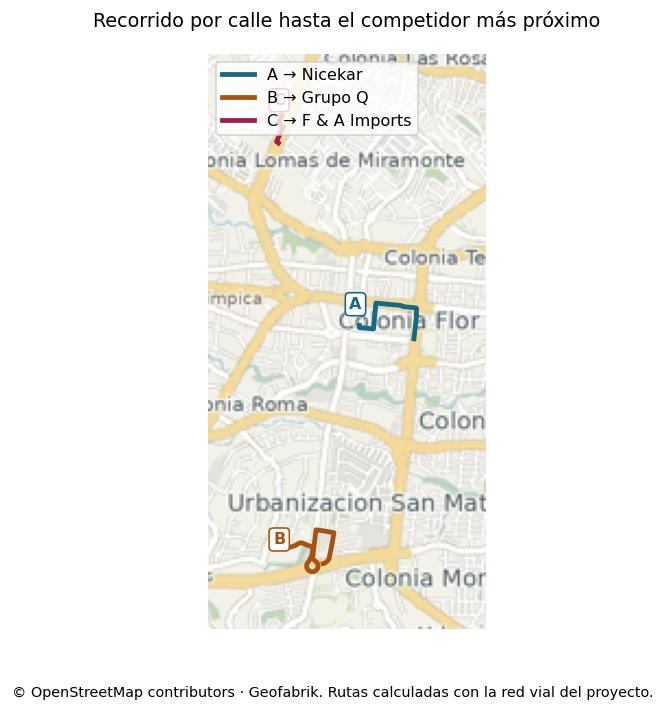

In [13]:
fig, ax = plt.subplots(figsize=(10, 6.5))
mapa_base(ax)
extremos = []
for u, color in zip(ubic.itertuples(), ["#176785", "#a55313", "#a01e4b"]):
    origen, _ = nodo_y_separacion(u.longitude, u.latitude)
    mas_cercano = vial.loc[vial.id == u.id, "mas_cercano"].iloc[0]
    destino = next(n for nombre,n,_ in destinos if nombre == mas_cercano)
    ruta = nx.shortest_path(G, origen, destino, weight="length")
    trazado = []
    for a,b in zip(ruta, ruta[1:]):
        tramo = min(G[a][b].values(), key=lambda t:t["length"])
        coords = list(tramo["geometry"].coords) if "geometry" in tramo else [(G.nodes[n]["x"],G.nodes[n]["y"]) for n in (a,b)]
        if math.dist(coords[-1], (G.nodes[a]["x"],G.nodes[a]["y"])) < math.dist(coords[0], (G.nodes[a]["x"],G.nodes[a]["y"])):
            coords.reverse()
        trazado.extend(coords)
    if trazado:
        xx,yy = web.transform(*zip(*trazado))
        ax.plot(xx,yy,color=color,lw=3,label=f"{u.id} → {mas_cercano}")
        extremos.extend(zip(xx,yy))
    x,y = web.transform(u.longitude,u.latitude)
    extremos.append((x,y))
    ax.annotate(u.id,(x,y),xytext=(-6,4),textcoords="offset points",color=color,weight="bold",
                bbox=dict(boxstyle="round,pad=.25",fc="white",ec=color))
x,y = np.array(extremos).T
ax.set(xlim=(x.min()-500,x.max()+500),ylim=(y.min()-420,y.max()+420), title="Recorrido por calle hasta el competidor más próximo")
ax.legend(loc="upper left")
ax.set_axis_off()
fig.text(.5,.02,"© OpenStreetMap contributors · Geofabrik. Rutas calculadas con la red vial del proyecto.",ha="center",fontsize=9)
plt.show()

La ruta comienza en el nodo de calle más cercano a la propuesta. En A el competidor más próximo por calle es Nicekar, a unos 812 m. En B queda a 172 m y en C a 231 m. La red mide recorridos entre nodos, por lo que el establecimiento más cercano por calle puede ser distinto del más cercano en línea recta.

## 12. Comparación final

Unimos la clasificación, la población distrital y los dos tipos de distancia. La primera gráfica cuenta negocios dentro de un círculo. La segunda cuenta los que alcanzamos por calles. Ambas usan la misma escala de conteo.

,id,zona_knn,a_500m,a_1km,a_2km,mas_cercano_m,tercer_vecino_m,distrito,poblacion_2024,a_1km_por_calle,a_2km_por_calle,mas_cercano_por_calle_m
0,A,Zona 1,1,5,16,400.4,559.9,San Salvador,330543,1,10,811.9
1,B,Zona 2,10,10,13,185.2,235.9,San Salvador,330543,4,9,172.0
2,C,Zona 1,2,2,9,76.7,1234.0,San Salvador,330543,2,6,231.1


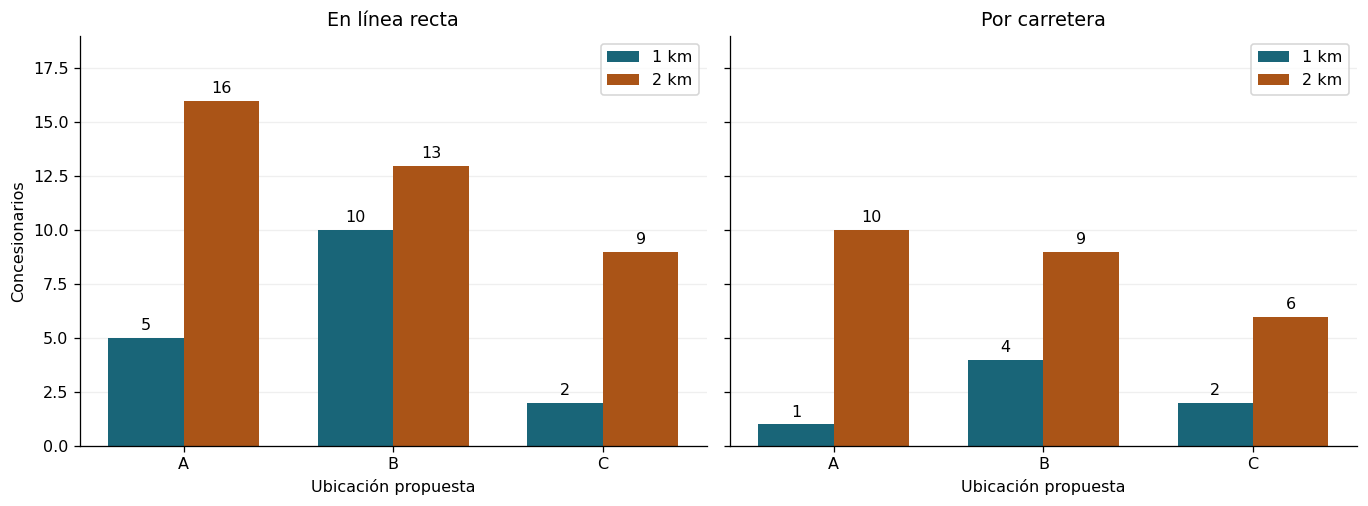

In [14]:
resultados = (clasificacion.merge(unidos[["id","distrito"]],on="id")
              .merge(censo[["distrito","poblacion_2024"]],on="distrito")
              .merge(vial[["id","a_1km_por_calle","a_2km_por_calle","mas_cercano_m"]]
                     .rename(columns={"mas_cercano_m":"mas_cercano_por_calle_m"}),on="id"))
display(resultados)
fig, ejes = plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax, titulo, columnas in zip(ejes,["En línea recta", "Por carretera"],
                                [["a_1km","a_2km"],["a_1km_por_calle","a_2km_por_calle"]]):
    posiciones = np.arange(len(resultados))
    for i,(col,color) in enumerate(zip(columnas,["#196578","#aa5417"])):
        barras = ax.bar(posiciones+(i-.5)*.36,resultados[col],width=.36,color=color,label=f"{i+1} km")
        ax.bar_label(barras,padding=3)
    ax.set(title=titulo,xticks=posiciones,xticklabels=resultados.id, xlabel="Ubicación propuesta")
    ax.grid(axis="y",alpha=.2); ax.set_axisbelow(True)
    ax.legend()
ejes[0].set_ylabel("Concesionarios")
ejes[0].set_ylim(0,resultados[["a_1km","a_2km","a_1km_por_calle","a_2km_por_calle"]].max().max()+3)
plt.tight_layout()
plt.show()

## 13. Qué encontramos

De los 30 registros iniciales, usamos 21. K-Means formó dos zonas con 9 y 12 concesionarios. KNN asignó A y C a la Zona 1 y B a la Zona 2.

**Elegimos C como candidata preliminar** porque tiene el menor conteo en tres de las cinco medidas. A 1 km en línea recta contamos 2 competidores alrededor de C, frente a 5 en A y 10 en B. A 2 km contamos 9 en C, frente a 16 y 13. Por carretera, dentro de 2 km encontramos 6 en C y 10 en cada una de las otras propuestas.

A tiene el menor conteo a 500 m en línea recta y a 1 km por carretera. Además, C tiene un competidor a solo 77 m en línea recta. Por eso el resultado depende de la distancia que queramos estudiar.

## 14. Alcance de los resultados

OpenStreetMap puede omitir negocios o registrar comercios que necesitan verificación. La población del censo corresponde al distrito completo. Las rutas usan una red descargada y no incluyen tráfico en tiempo real. Para saber cuántos clientes atraería cada propuesta harían falta datos de demanda por zona.

## 15. Fuentes

Esta tabla identifica el origen de los datos y de la cartografía. El mapa de contexto y la red que usamos para calcular recorridos están documentados por separado.

In [15]:
fuentes = pd.read_csv(RAIZ / "fuentes" / "fuentes_datos.csv")
fuentes[["id", "dato", "tipo", "fuente", "fecha_consulta", "url"]]

,id,dato,tipo,fuente,fecha_consulta,url
0,F01,Población 2024 por distrito del departamento d...,observado,BCR - VII Censo de Población y VI de Vivienda ...,2026-11-13,https://diario.elmundo.sv/economia/esta-es-la-...
1,F02,Población 2024 distritos de La Libertad Este,observado,citypopulation.de con fuente ONEC/BCR,2026-11-13,https://www.citypopulation.de/en/elsalvador/mu...
2,F03,Población 2024 distritos de La Libertad Sur,observado,citypopulation.de con fuente ONEC/BCR,2026-11-13,https://www.citypopulation.de/en/elsalvador/mu...
3,F04,Población municipio San Salvador Centro,observado,Ferrufino C. (2025) Revista ECA 80(783) UCA,2026-11-13,https://revistas.uca.edu.sv/index.php/eca/arti...
4,F05,Hogares con vehículo departamento de San Salvador,observado,Diario El Mundo con datos del Censo 2024 (BCR),2026-11-13,https://diario.elmundo.sv/economia/la-mitad-de...
5,F06,Parque vehicular (nacional y distrito San Salv...,observado,Observatorio Nacional de Seguridad Vial (citad...,2026-11-13,https://www.eldiariodehoy.com/?p=55849
6,F14,Ubicación del Porsche Center existente,observado,Porsche Finder El Salvador,2026-11-13,https://finder.porsche.com/sv/es-SV/details/2X...
7,F15,Distribuidor de Porsche en El Salvador,observado,El Diario de Hoy / Porsche Newsroom,2026-11-13,https://www.elsalvador.com/?p=1220161
8,F16,Establecimientos shop=car,observado,OpenStreetMap vía Overpass Turbo (ODbL),2026-11-09,https://www.openstreetmap.org/copyright
9,F17,Límites distritales,observado,OPAMSS - Oficina de Planificación del Área Met...,2026-11-09,https://opamss.org.sv
